In [1]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [59]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

#Constants
D = 0.15
rho = 7800
lamda = 10000
gamma = 0.25
g = 9.8

#Initial conditions 
v0 = 300
theta = np.radians(50) 

x0 = 0 
y0 = 0

vx0 = v0 * np.cos(theta)
vy0 = v0 * np.sin(theta)

#Drag co-efficent 
def c(y):
 return gamma * D**2 * np.exp(-y / lamda)

#Mass
m = (rho * np.pi * D**3)/6

#Solving ODE
def equations(t, state):
    x, y ,vx, vy = state 

    v = np.sqrt(vx**2 + vy **2)

    dxdt = vx
    dydt = vy

    dvxdt = -(c(y)/m) * v * vx 
    dvydt = -g - (c(y)/m) * v *vy

    return [dxdt, dydt, dvxdt, dvydt]

inital = [x0, y0, vx0, vy0]

t = np.linspace(0, 32, 1000)

sol = solve_ivp(
    equations,
    (0, 32),
    inital,
    t_eval=t,
    dense_output=True
)


x = sol.y[0]
y = sol.y[1]


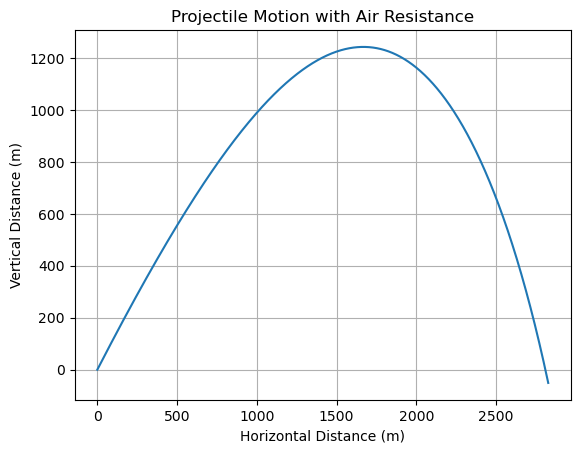

In [60]:
plt.plot(x, y)
plt.xlabel("Horizontal Distance (m)")
plt.ylabel("Vertical Distance (m)")
plt.title("Projectile Motion with Air Resistance")
plt.grid()
plt.show()

In [57]:
#Use Brents method to find range and land time  
from scipy.optimize import brentq 

def R(t):
    return sol.sol(t)[1]
t_land = brentq(R, 0.01, 44)

print ("Time cannon ball hit ground", t_land, "seconds")

#Range
range_x = sol.sol(t_land)[0] - x0

print("Horizontal range:", range_x, "meters")

Time cannon ball hit ground 31.584639309395374 seconds
Horizontal range: 2809.660049671035 meters


In [ ]:
t_plot = np.linspace(0, t_land, 300)

x_plot = sol.sol(t_plot)[0]
y_plot = sol.sol(t_plot)[1]

plt.plot(x_plot, y_plot)
plt.xlabel("Horizontal Distance (m)")
plt.ylabel("Vertical Distance (m)")
plt.title("Cannonball Trajectory")

plt.grid()
plt.show()

In [69]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

#Constants
D = 0.15
rho = 7800
lamda = 10000
gamma = 0.25
g = 9.8

#Initial conditions 
v0 = 300
theta = np.radians(50) 

x0 = 0 
y0 = 0

vx0 = v0 * np.cos(theta)
vy0 = v0 * np.sin(theta)

#Drag co-efficent 
def c(y):
 return gamma * D**2 

#Mass
m = (rho * np.pi * D**3)/6

#Solving ODE
def equations(t, state):
    x, y ,vx, vy = state 

    v = np.sqrt(vx**2 + vy **2)

    dxdt = vx
    dydt = vy

    dvxdt = -(c(y)/m) * v * vx 
    dvydt = -g - (c(y)/m) * v *vy

    return [dxdt, dydt, dvxdt, dvydt]

inital = [x0, y0, vx0, vy0]

t = np.linspace(0, 32, 1000)

sol = solve_ivp(
    equations,
    (0, 32),
    inital,
    t_eval=t,
    dense_output=True
)


x = sol.y[0]
y = sol.y[1]


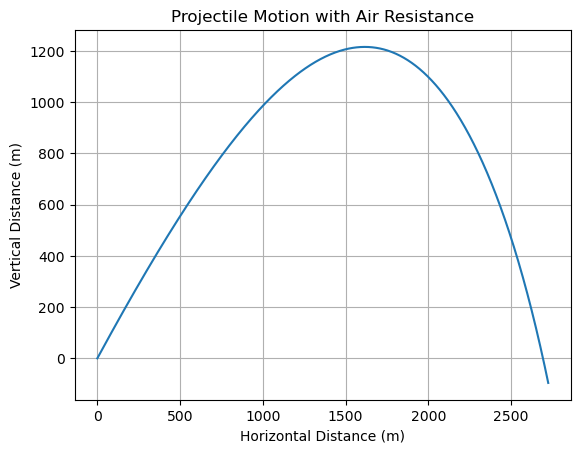

In [70]:
plt.plot(x, y)
plt.xlabel("Horizontal Distance (m)")
plt.ylabel("Vertical Distance (m)")
plt.title("Projectile Motion with Air Resistance")
plt.grid()
plt.show()

In [71]:
from scipy.optimize import brentq 

def R(t):
    return sol.sol(t)[1]
t_land = brentq(R, 0.01, 32)

print ("Time cannon ball hit ground", t_land, "seconds")

#Range
range_x = sol.sol(t_land)[0] - x0

print("Horizontal range:", range_x, "meters")

Time cannon ball hit ground 31.20764022127212 seconds
Horizontal range: 2691.8017300492816 meters


In [76]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

#Constants
D = 0.15
rho = 7800
lamda = 10000
gamma = 0.25
g = 9.8

#Initial conditions 
v0 = 300
theta = np.radians(50) 

x0 = 0 
y0 = 0

vx0 = v0 * np.cos(theta)
vy0 = v0 * np.sin(theta)

#Drag co-efficent 
def c(y):
 return 0

#Mass
m = (rho * np.pi * D**3)/6

#Solving ODE
def equations(t, state):
    x, y ,vx, vy = state 

    v = np.sqrt(vx**2 + vy **2)

    dxdt = vx
    dydt = vy

    dvxdt = -(c(y)/m) * v * vx 
    dvydt = -g - (c(y)/m) * v *vy

    return [dxdt, dydt, dvxdt, dvydt]

inital = [x0, y0, vx0, vy0]

t = np.linspace(0, 47, 1000)

sol = solve_ivp(
    equations,
    (0, 47),
    inital,
    t_eval=t,
    dense_output=True
)


x = sol.y[0]
y = sol.y[1]


In [77]:
from scipy.optimize import brentq 

def R(t):
    return sol.sol(t)[1]
t_land = brentq(R, 0.01, 100)

print ("Time cannon ball hit ground", t_land, "seconds")

#Range
range_x = sol.sol(t_land)[0] - x0

print("Horizontal range:", range_x, "meters")

Time cannon ball hit ground 46.90068019095791 seconds
Horizontal range: 9044.15283378561 meters


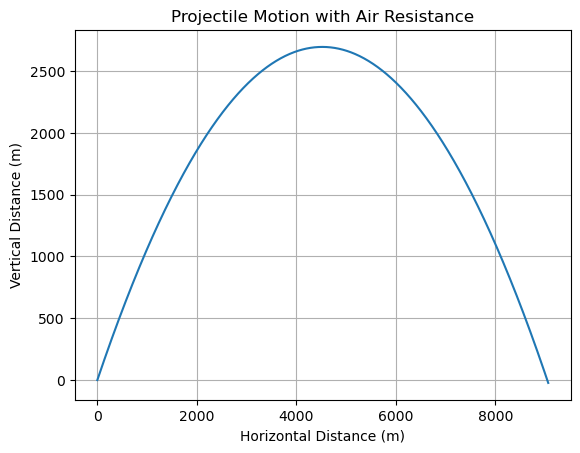

In [78]:
plt.plot(x, y)
plt.xlabel("Horizontal Distance (m)")
plt.ylabel("Vertical Distance (m)")
plt.title("Projectile Motion with Air Resistance")
plt.grid()
plt.show()

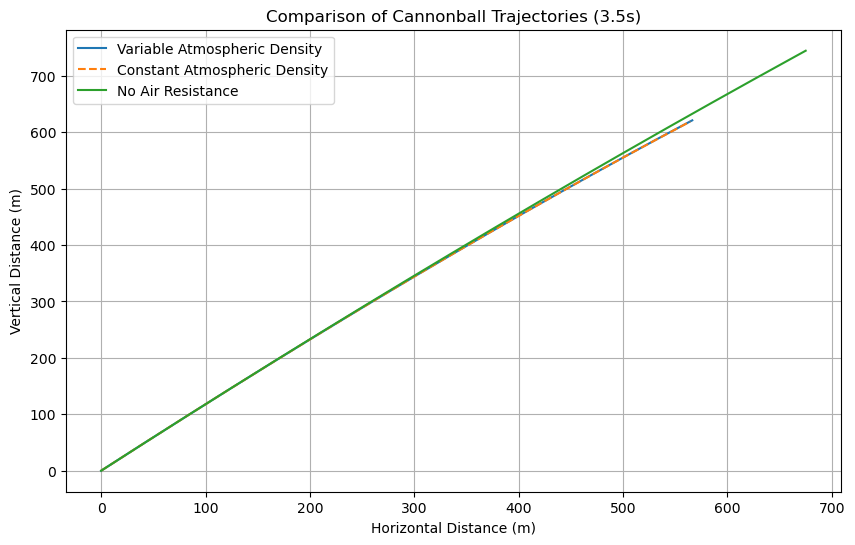

In [94]:
# Inital Trojectory until 3.5s

t = np.linspace(0, 3.5, 1000)


# ODE's
def equations(t, state, case):
    x, y, vx, vy = state

    v = np.sqrt(vx**2 + vy**2)

    # Drag co-efficent 
    if case == 1:
        c = gamma * D**2 * np.exp(-y / lamda)
    elif case == 2:
        c = gamma * D**2
    else:
        c = 0

    dxdt = vx
    dydt = vy

    dvxdt = -(c/m) * v * vx
    dvydt = -g - (c/m) * v * vy

    return [dxdt, dydt, dvxdt, dvydt]


# Time interval
t = np.linspace(0, 3.5, 1000)

# c(y)
sol1 = solve_ivp(
    equations, (0, 3.5), inital,
    args=(1,), t_eval=t
)

# C(0)
sol2 = solve_ivp(
    equations, (0, 3.5), inital,
    args=(2,), t_eval=t
)

# No Air resistence 
sol3 = solve_ivp(
    equations, (0, 3.5), inital,
    args=(3,), t_eval=t
)


plt.figure(figsize=(10, 6))

plt.plot(sol1.y[0], sol1.y[1],
         label="Variable Atmospheric Density")

plt.plot(sol2.y[0], sol2.y[1],
         label="Constant Atmospheric Density",
         linestyle="--")

plt.plot(sol3.y[0], sol3.y[1],
         label="No Air Resistance")

plt.xlabel("Horizontal Distance (m)")
plt.ylabel("Vertical Distance (m)")
plt.title("Comparison of Cannonball Trajectories (3.5s)")
plt.legend()
plt.grid()
plt.show()

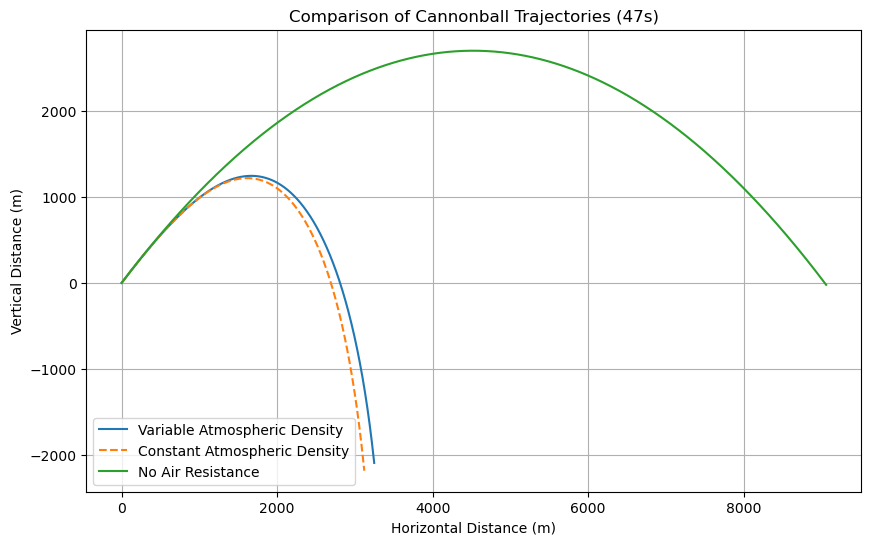

In [95]:
# Full trojectory with full horizontal range 

t = np.linspace(0, 47, 1000)


# ODE's
def equations(t, state, case):
    x, y, vx, vy = state

    v = np.sqrt(vx**2 + vy**2)

    # Drag co-efficent 
    if case == 1:
        c = gamma * D**2 * np.exp(-y / lamda)
    elif case == 2:
        c = gamma * D**2
    else:
        c = 0

    dxdt = vx
    dydt = vy

    dvxdt = -(c/m) * v * vx
    dvydt = -g - (c/m) * v * vy

    return [dxdt, dydt, dvxdt, dvydt]


# Time interval
t = np.linspace(0, 47, 1000)

# c(y)
sol1 = solve_ivp(
    equations, (0, 47), inital,
    args=(1,), t_eval=t
)

# C(0)
sol2 = solve_ivp(
    equations, (0, 47), inital,
    args=(2,), t_eval=t
)

# No Air resistence 
sol3 = solve_ivp(
    equations, (0, 47), inital,
    args=(3,), t_eval=t
)


plt.figure(figsize=(10, 6))

plt.plot(sol1.y[0], sol1.y[1],
         label="Variable Atmospheric Density")

plt.plot(sol2.y[0], sol2.y[1],
         label="Constant Atmospheric Density",
         linestyle="--")

plt.plot(sol3.y[0], sol3.y[1],
         label="No Air Resistance")

plt.xlabel("Horizontal Distance (m)")
plt.ylabel("Vertical Distance (m)")
plt.title("Comparison of Cannonball Trajectories (47s)")
plt.legend()
plt.grid()
plt.show()